# importowanie potrzebnych narzędzi, aby wykonać analizę i wizualizację

In [12]:
import csv

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# wszystkie dostępne funkcje

In [13]:
DISTANCE = 7
DICT = {
    "rdul": 0,
    "rdlu": 1,
    "drul": 2,
    "drlu": 3,
    "ludr": 4,
    "lurd": 5,
    "uldr": 6,
    "ulrd": 7
}
def split_data(table):
    t = [[] for _ in range(8)]
    for row in table:
        strategy = row[3]
        temp = [row[0], row[4], row[5], row[6], row[7], row[8]]
        t[DICT[strategy]].append(temp)
    return t

def split_astr(table):
    manh = []
    hamm = []
    for row in table:
        temp = [row[0], row[4], row[5], row[6], row[7], row[8]]
        strategy = row[3]
        if strategy == "manh":
            manh.append(temp)
        elif strategy == "hamm":
            hamm.append(temp)

    return [hamm, manh]


def general_trim(table):
    data = [[] for _ in range(DISTANCE)]
    for row in table:
        data[row[0] - 1].append(np.array(row[1:]))
    return data


def calculate(table):
    data = []
    for i in range(len(table)):
        data.append(np.divide(np.sum(table[i], axis=0), len(table[i])))
    return np.array(data)


def categorised_avg(table):
    category = []
    category_avg = []
    for x in range(len(table)):
        category.append(general_trim(table[x]))
        category_avg.append(calculate(category[x]))
    return category_avg


def general_avg(table):
    general_sum = [np.array([table[i][x] for i in range(len(table))]) for x in range(DISTANCE)]
    distance_category_avg = []
    for i in range(len(general_sum)):
        distance_category_avg.append(np.divide(np.sum(general_sum[i], axis=0), len(general_sum[i])))
    return distance_category_avg


def get_data(table, index):
    return [table[i][index] for i in range(len(table))]


def read_file(file):
    data = []
    with open(file, 'r', newline='') as csvfile:
        csvreader = csv.reader(csvfile, delimiter=' ')
        for row in csvreader:
            data_row = [int(row[0]), int(row[1]), row[2], row[3], int(row[4]), int(row[5]), int(row[6]), int(row[7]),
                        float(row[-1])]
            data.append(data_row)

    return data


def transpose(table):
    tranposed = []
    for i in range(len(table)):
        tranposed.append(np.transpose(table[i]))
    return tranposed


def bar_plot(ax, data, key, feature, title, ylabel, total_width=0.8, single_width=1, legend=True, log_scale=False):
    sns.set(style="darkgrid")  # Ustawienie stylu Seaborn
    colors = sns.color_palette()
    n_bars = len(data)
    bar_width = total_width / n_bars
    x = np.array([1, 2, 3, 4, 5, 6, 7])
    for i in range(n_bars):
        x_offset = (i - n_bars / 2) * bar_width + bar_width / 2
        ax.bar(x + x_offset, np.array(data[i][feature]), width=bar_width * single_width, color=colors[i % len(colors)])
    if legend:
        if len(key) > 4:
            ax.legend(key, loc='upper left', ncol=2)
        else:
            ax.legend(key, loc='upper left')
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    if log_scale:
        ax.set_yscale('log')

# wywolywanie funkcji w main

In [14]:
filename = './Result.csv'

array = read_file(filename)
bfs = []
dfs = []
astr = []
for r in array:
    if r[2] == 'astr':
        astr.append(r)
    if r[2] == 'bfs':
        bfs.append(r)
    if r[2] == 'dfs':
        dfs.append(r)

bfs_categorised = split_data(bfs)
dfs_categorised = split_data(dfs)
astr_categorised = split_astr(astr)

bfs_strategy_avg = categorised_avg(bfs_categorised)
bfs_general_avg = general_avg(bfs_strategy_avg)

dfs_strategy_avg = categorised_avg(dfs_categorised)
dfs_general_avg = general_avg(dfs_strategy_avg)

astr_strategy_avg = categorised_avg(astr_categorised)
astr_general_avg = general_avg(astr_strategy_avg)

for line in bfs_general_avg:
    print(line)
print()

for line in dfs_general_avg:
    print(line)
print()

for line in astr_general_avg:
    print(line)

LENGTH = 0
VISITED_STATES = 1
PROCESSED_STATES = 2
MAX_DEPTH = 3
TIME = 4

dfs_t = transpose(dfs_strategy_avg)
bfs_t = transpose(bfs_strategy_avg)
astr_t = transpose(astr_strategy_avg)

general_avg = transpose([bfs_general_avg, dfs_general_avg, astr_general_avg])

keys = ['RDUL', 'RDLU', 'DRUL', 'DRLU', 'LUDR', 'LURD', 'ULDR', 'ULRD']
metric = ['Hamming', 'Manhattan']
LABELS = ['Długość rozwiązania', 'Stany odwiedzone', 'Stany przetworzone', 'Maksymalne głębokość', 'Czas [ms]']
params = [LENGTH, VISITED_STATES, PROCESSED_STATES, MAX_DEPTH, TIME]

[5.7500000e+00 1.1320275e+05 8.6049125e+04 6.7500000e+00 3.5921250e+00]
[2.0000e+00 2.0500e+01 1.0625e+01 3.0000e+00 5.9375e-04]
[3.0000e+00 4.5700e+01 2.3300e+01 4.0000e+00 1.2625e-03]
[4.00000000e+00 9.47500000e+01 4.62500000e+01 5.00000000e+00
 2.49479167e-03]
[5.00000000e+00 1.91203704e+02 9.21666667e+01 6.00000000e+00
 4.96064815e-03]
[6.00000000e+00 4.04518692e+02 1.94911215e+02 7.00000000e+00
 1.03633178e-02]
[7.00000000e+00 8.78688679e+02 4.21426887e+02 8.00000000e+00
 2.26768868e-02]

[6.33333333e+00 7.90704708e+05 9.22559083e+05 7.33333333e+00
 2.85944167e+01]
[1.10000000e+01 1.37911938e+05 1.54265625e+05 1.20000000e+01
 4.61103125e+00]
[1.22500000e+01 2.64408062e+05 2.98597662e+05 1.32500000e+01
 8.96656250e+00]
[1.52083333e+01 2.27144333e+05 2.55530286e+05 1.62083333e+01
 7.62297917e+00]
[1.55555556e+01 3.21754236e+05 3.63543505e+05 1.65555556e+01
 1.08424838e+01]
[1.69252336e+01 2.50931496e+05 2.82248778e+05 1.79252336e+01
 8.39611332e+00]
[1.58136792e+01 3.69510692e+05 4.

# rysowanie wykresow

### dlugosc znalezionego rozwiazania

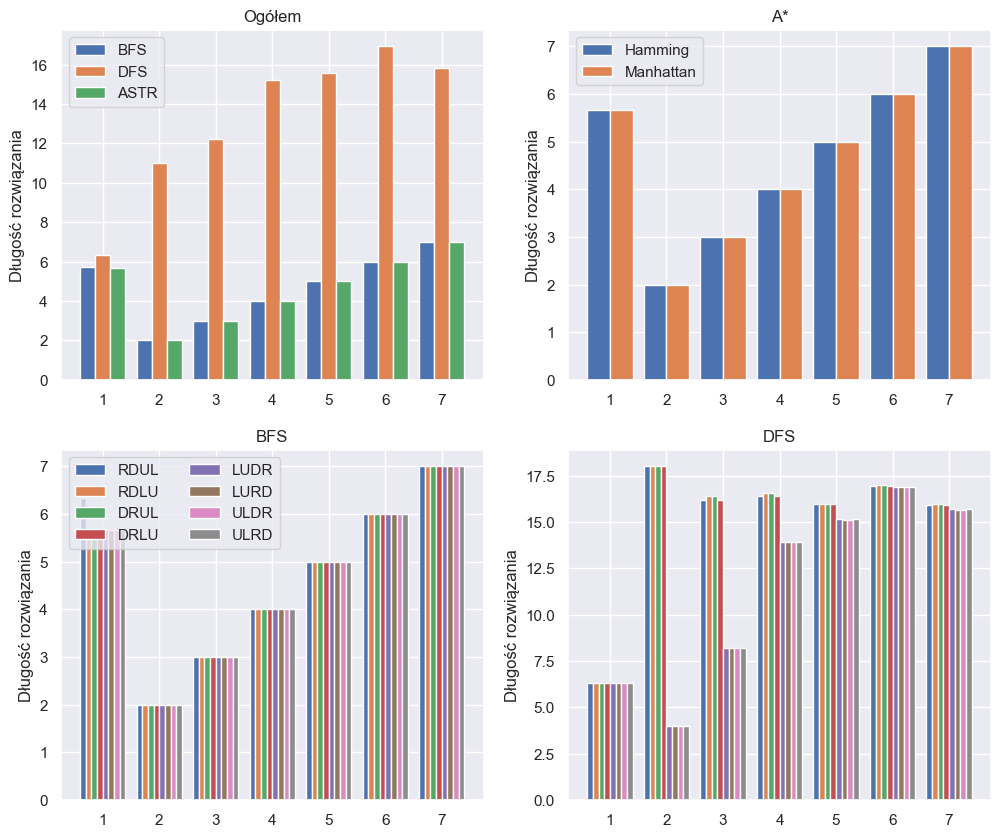

In [15]:
axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))[1]
bar_plot(axes[0][0], general_avg, ['BFS', 'DFS', 'ASTR'], LENGTH, "Ogółem", LABELS[0], total_width=.8)
bar_plot(axes[0][1], astr_t, metric, LENGTH, "A*", LABELS[0], total_width=.8)
bar_plot(axes[1][0], bfs_t, keys, LENGTH, "BFS", LABELS[0], total_width=.8)
bar_plot(axes[1][1], dfs_t, keys, LENGTH, "DFS", LABELS[0], total_width=.8, legend=False)
plt.show()

## liczba stanow odwiedzonych

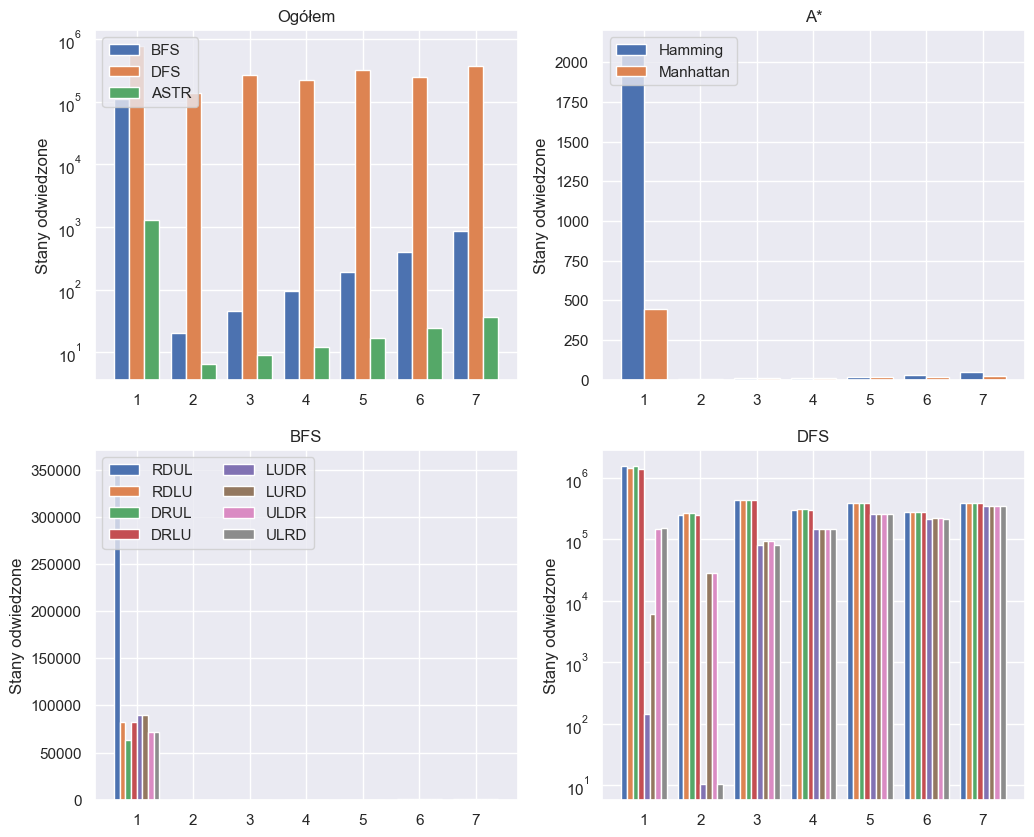

In [16]:
axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))[1]
bar_plot(axes[0][0], general_avg, ['BFS', 'DFS', 'ASTR'], VISITED_STATES, "Ogółem", LABELS[1], total_width=.8,
         log_scale=True)
bar_plot(axes[0][1], astr_t, metric, VISITED_STATES, "A*", LABELS[1], total_width=.8)
bar_plot(axes[1][0], bfs_t, keys, VISITED_STATES, "BFS", LABELS[1], total_width=.8)
bar_plot(axes[1][1], dfs_t, keys, VISITED_STATES, "DFS", LABELS[1], total_width=.8, log_scale=True, legend=False)
plt.show()

## liczba stanow przetworzonych

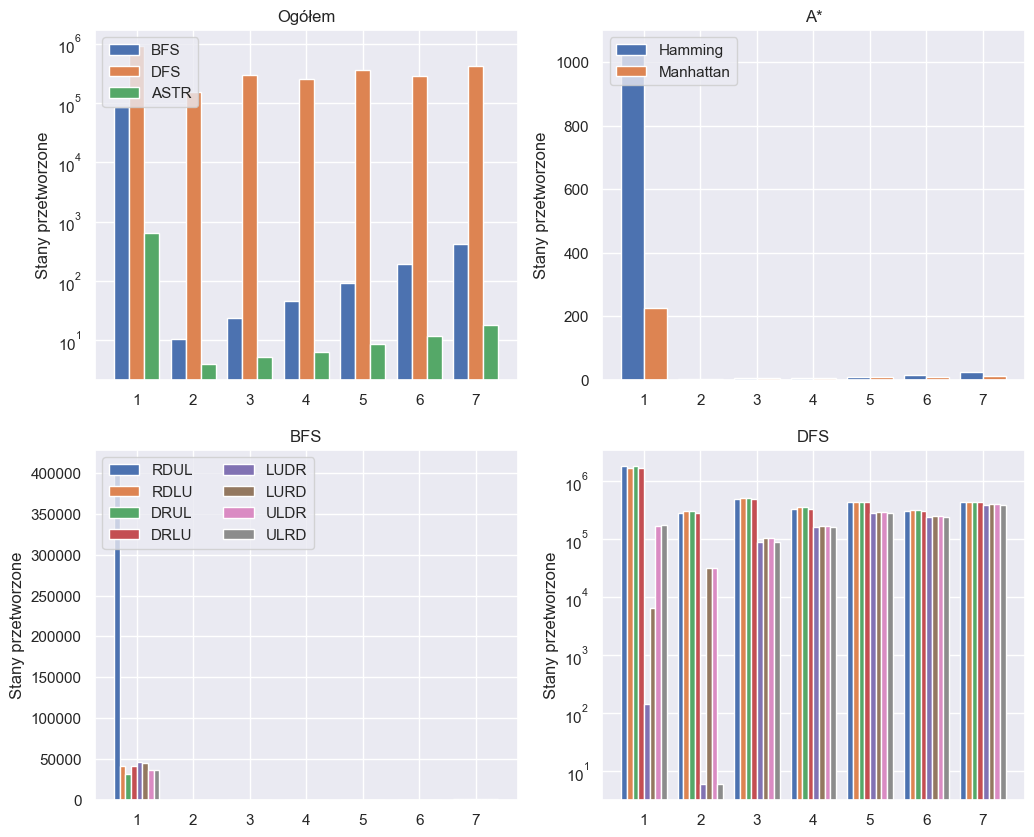

In [17]:
axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))[1]
bar_plot(axes[0][0], general_avg, ['BFS', 'DFS', 'ASTR'], PROCESSED_STATES, "Ogółem", LABELS[2], total_width=.8,
         log_scale=True)
bar_plot(axes[0][1], astr_t, metric, PROCESSED_STATES, "A*", LABELS[2], total_width=.8)
bar_plot(axes[1][0], bfs_t, keys, PROCESSED_STATES, "BFS", LABELS[2], total_width=.8)
bar_plot(axes[1][1], dfs_t, keys, PROCESSED_STATES, "DFS", LABELS[2], total_width=.8, log_scale=True, legend=False)

## maksymalna osiągnięta głębokość rekursji

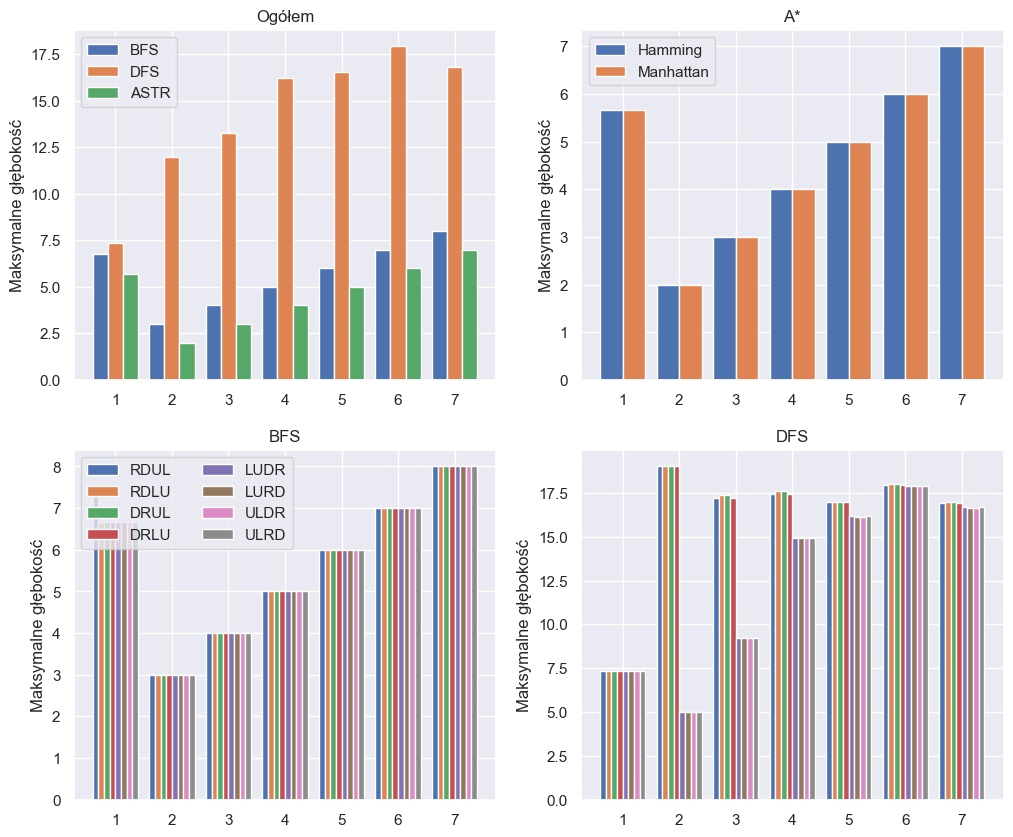

In [18]:
axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))[1]
bar_plot(axes[0][0], general_avg, ['BFS', 'DFS', 'ASTR'], MAX_DEPTH, "Ogółem", LABELS[3], total_width=.8)
bar_plot(axes[0][1], astr_t, metric, MAX_DEPTH, "A*", LABELS[3], total_width=.8)
bar_plot(axes[1][0], bfs_t, keys, MAX_DEPTH, "BFS", LABELS[3], total_width=.8)
bar_plot(axes[1][1], dfs_t, keys, MAX_DEPTH, "DFS", LABELS[3], total_width=.8, legend=False)

## czas trwania procesu obliczeniowego

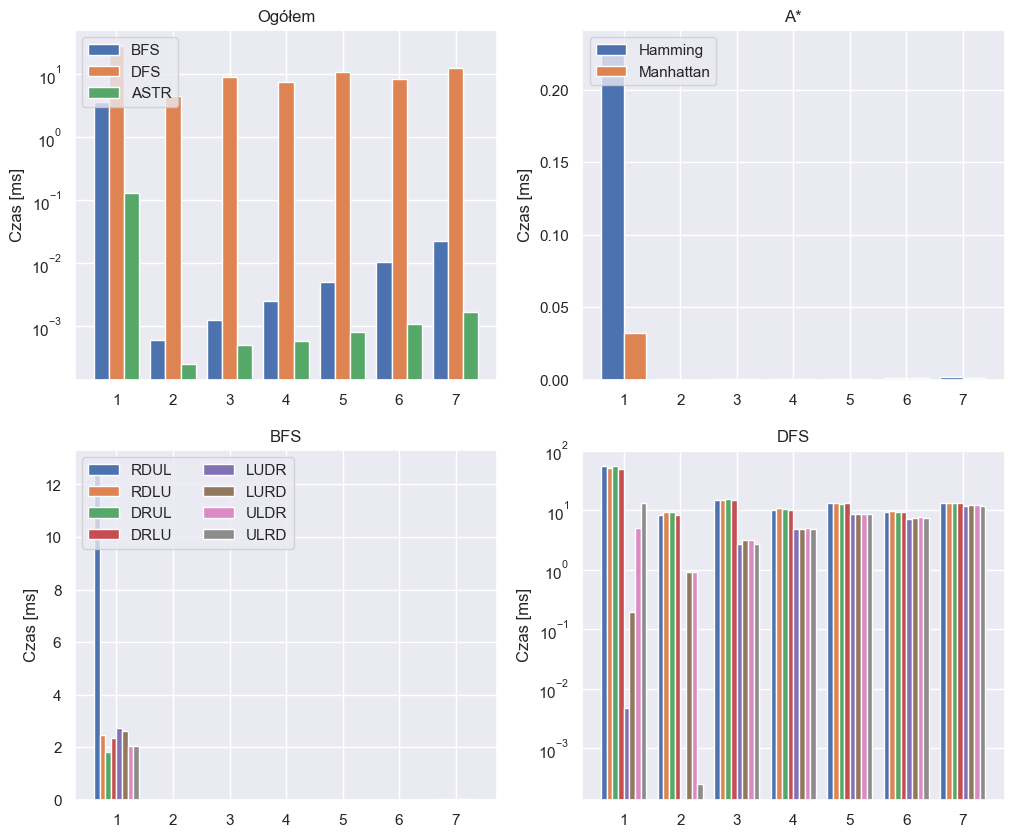

In [19]:
axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))[1]
bar_plot(axes[0][0], general_avg, ['BFS', 'DFS', 'ASTR'], TIME, "Ogółem", LABELS[4], total_width=.8, log_scale=True)
bar_plot(axes[0][1], astr_t, metric, TIME, "A*", LABELS[4], total_width=.8)
bar_plot(axes[1][0], bfs_t, keys, TIME, "BFS", LABELS[4], total_width=.8)
bar_plot(axes[1][1], dfs_t, keys, TIME, "DFS", LABELS[4], total_width=.8, log_scale=True, legend=False)